# Sample selection

The random sample dataset is composed of marginal ice zone (MIZ) locations and dates from 9 Arctic regions. The dates are selected based on the climatology of sea ice cover for each region. Each scene is 100 km by 100 km and centered on a location where the NSIDC climate data record v5 (CDR) of sea ice concentration shows between 15 and 85%. The CDR is used to find candidate samples, as the dataset can be accessed quickly and covers the full time period for sampling. Since the resolution is 25 km, each candidate scene only contains a few CDR pixels. We refine the candidate samples by computing the sea ice cover from the MASIE 4 km data.

Only scenes with at least 25% sea ice fraction (area with SIC > 15%) are considered. 

MODIS images are available since 2000 (terra) and 2002 (aqua), however the MASIE sea ice extent imagery is only available since 2006. So we draw our sample from 2006 to 2023 (the last full year of NSIDC data at time of writing).

Sample selection needs to balance two competing issues:
(a) the size of the image needs to be large enough that there is a useful range of floe sizes that can be resolved
(b) the number of scenes should be large enough that we can consider it a representative random sample
Because the time needed to manually annotate an image is proportional to the image area, the number of images that can be analyzed is strongly limited by the image size. 

First, nine regions spanning the circumpolar Arctic seasonal ice zones were selected (Figure 1, Table 1). The regions were selected to have equal area. The file `setup_locations.py` makes a CSV file `data/metadata/region_definitions.csv`.

We perform stratified random sampling to select a set of images for the validation dataset.
We use the NSIDC Sea Ice Concentration Climate Data Record (SIC CDR) to identify periods of time that each region contains some overlap with the sea ice region. We acknowledge that uncertainty in SIC CDR is high during the summer. Since the purpose of using the SIC CDR in the random sampling is to find a wide range of sea ice conditions, rather than to make inferences about sea ice physics in these regions, we consider the SIC CDR suitable for this purpose.

Within each region, we follow the following procedure
* Randomly choose a start year and a date between March and region-specific end date (max September 30)
* Select a center point (x, y) from the CDR grid that is at least 50 km from the region border
* Calculate sea ice fraction for the 100 km box centered at the point
* If the sea ice fraction is at least 0.25, add date and center point to list of cases
* Check the number of cases.
   * If the minimum number of cases per month is met, move to the next region.
    
We start by generating a set of samples larger than is needed for the validation dataset, saving 10 candidate cases per month, per region. We then stratify the sample to get minimum 3 samples per month, with randomly chosen additional samples chosen to bring the number to 21 dates per region for locations where sea ice is present less than 7 months of the summer. Thus, there are more samples for March in the Sea of Okhostk than in the Beaufort Sea.

## History of dataset development
Developing the random sample dataset began in Spring 2024. Initial samples were drawn using the same functions as below, but for equal-area regions. Because the region boundaries overlapped, some points had ambiguous region membership. We also found cases where the sea ice concentration data from the NSIDC was biased high, due to issues with proximity to the coast. 

We include some samples drawn from the same sampling procedure with slightly different region definitions. We refined the region definitions to avoid overlaps and to align better with the IHO marginal sea definitions, and we extended the time range an additional year. To ensure that the sampling was still random according to the procedure described above, we drew a large set of new sample locations, then computed the relative fraction within the old domain and with the modified domain. Using the relative fractions from the overlapping and non-overlapping regions, we drew samples from the new regions until the proportion was correct.

The code below takes the original sample, used in the Simon Hatcher's batchelor's thesis (Hatcher 2024), then resamples the region to create a random sample representative of the new region. Consider a region $X$ and a new, overlapping region $Y$. We posses a sample of $n_X$ points from region $X$ and wish to form a sample of points from $Y$. Drawing a random sample of $m$ points from $Y$, we separate them into $m_{X}$ points from $Y \cap X$ (i.e., the points in $Y$ that are also in $X$), and $m_{Y \setminus X}$ points that are in region of $Y$ excluding $X$. Thus, $m_X + m_{Y \setminus X} = n_{Y} = n_{X}$. To extend our original sample, we randomly select up to $m_X$ points from the $n_X$ original points. If $n_X < m_X$, we replace $n_X$ points from the $m_X$ new points with points from the old sample, and keep $m_X - n_X$ points from the new sample. If $n_X >= m_X$, we draw $m_X$ of the originally sampled points at random to keep in the new sample.




# Defining the regions
We define our sampling regions based on the International Hydrographic Organization (IHO) Limits of Oceans and Seas. As the satellite data is provided in polar stereographic coordinates, we select rectangular regions with bounds selected from the landmarks dividing the IHO defined seas. Thus, the boundaries are not intended to be exactly identical to the IHO seas. Boundaries are defined in the script `setup_locations.py`. An image is below. Examples of boundaries:

Greenland Sea:
- Northern bound is the line from northernmost point of Spitzbergen to the Northernmost part of Greenland.
- Eastern bound is the west coast of West Spitzbergen and Jan Mayen.
- Southern bound is Iceland.

Barents Sea: 
- West bound is line joining West Spitzbergen to Bear Island to North Cape of norway.
- Northwest bound is West Spitzbergen to Cape Leigh Smith.
- North bound across Bolshoy Ostrov, Alexandra Land, and northern coast of Franz-Josef Land.
- West coasts of Novaya Zemlya.

Kara Sea:
- Bounded on the north by Severnaya Zemlya
- Bounded on the east by Komsomolets Island and Bolshevik Island.

Barents-Kara Seas Joint Region:
- Use the north extent of the Greenland Sea as the lower bound for the Barents-Kara region
- Use the center of Severnaya Zemlya as the left extent.
- Upper bound is the Tamyr Peninsula.
- Right bound is the entrance to the White Sea.

Laptev Sea: 
- Left extent is the New Siberian Islands
- Right extent limited by BK seas region
- North extent Severnaya Zemlya

East siberian sea:
- Bounded on the left by Wrangel Island
- Bounded on the right by the New Siberian Islands
- Bottom boundary -- we go all the way to Point Barrow in polar stereographic coordinates
- Upper extent the russian mainland.

Bering-Chukchi Seas: 
- Right extent is Wrangel Island
- Lower extent is Point Barrow.
- Extended domain 1500 km to the left and upwards. 

## Load the regions

In [34]:
import os
import pyproj
import numpy as np
import pandas as pd
import xarray as xr

In [41]:
# Load sea ice fraction data
sif_data = pd.read_csv('../data/metadata/daily_sea_ice_fraction.csv', index_col=0, parse_dates=True)
threshold = 0.05
end_doy = sif_data.groupby(sif_data.index.dayofyear).quantile(0.90).apply(lambda x: x[x >= threshold].index.max())
start_doy = pd.Series(pd.to_datetime('2003-03-01').dayofyear, index=end_doy.index)

# Load region definitions and add start and end dates
regions = pd.read_csv('../data/metadata/region_definitions.csv', index_col=0)
regions.loc[end_doy.index, 'end_doy'] = end_doy.values
regions.loc[start_doy.index, 'start_doy'] = start_doy.values
regions.loc[start_doy.index, 'start_mmdd'] = (pd.to_timedelta(regions['start_doy'] - 1, unit='D') + pd.to_datetime('2001-01-01 00:00')).dt.strftime('%b %d')
regions.loc[end_doy.index, 'end_mmdd'] = (pd.to_timedelta(regions['end_doy'] - 2, unit='D') + pd.to_datetime('2001-01-01 00:00')).dt.strftime('%b %d')
regions.sort_values('center_lon').loc[:, ['start_doy', 'end_doy', 'start_mmdd', 'end_mmdd']].to_csv('../data/metadata/sample_start_end_times.csv')

In [42]:
regions.loc[:, ['center_lat', 'center_lon', 'start_mmdd', 'end_mmdd']].round(3)

,center_lat,center_lon,start_mmdd,end_mmdd
greenland_sea,74.698,-17.601,Mar 01,Sep 30
barents_kara_seas,75.617,53.223,Mar 01,Sep 30
laptev_sea,75.923,124.689,Mar 01,Sep 30
east_siberian_sea,75.171,165.192,Mar 01,Sep 30
bering_chukchi_seas,65.596,-169.076,Mar 01,Aug 23
beaufort_sea,74.860,-142.840,Mar 01,Sep 30
baffin_bay,74.768,-64.085,Mar 01,Sep 30
hudson_bay,58.143,-83.964,Mar 01,Aug 05
sea_of_okhostk,58.000,148.000,Mar 01,Jun 08


## Load functions for generating stratified random sample
These functions carry out the random sampling and sea ice fraction checks. The sampling is done iteratively, because there are multiple reasons that generated samples can be rejected. Samples are drawn by 
1. Picking a year at random
2. Picking a date from the months with fewer than 3 samples chosen
3. Selecting a center point from the MIZ using the 15-85% sea ice concentration region in the NSIDC SIC dataset

During the manual analysis of the downloaded images, there are a few reasons that a case can be rejected and replaced.
1. Image corrupted. MODIS coverage is generally excellent, but it can happen that an image is missing due to data problems.
2. Error in the NSIDC sea ice concentration. It is known that there are positive biases in SIC along coastlines, where there is mismatch between the details of the true coastline and the coarse mask used by the algorithm. For these regions, the MASIE ice extent is considered more reliable. However, each MASIE image is 37.8 MB making it prohibitive to access and calculate SIC at the initial sampling stage. We download and compute MASIE ice fraction for all the selected samples, and if MASIE shows 0 ice concentration and the visual analysis confirms it we reject the sample, drawing a new sample for the same location and same month.
3. Insufficient ocean area. The algorithms are run on regions outside a dilated landmask. In some cases, the landmask dilation results in 0 (or very few) analyzed pixels, so there is no region to compare.


In [63]:
sic_dataloc = '/Users/dwatkin2/Documents/research/data/nsidc_daily_cdr_v6/'
%run ../scripts/sampling_functions.py



In [48]:
df = pd.read_csv('../data/validation_dataset/validation_dataset.csv', parse_dates=['start_date'])

<Axes: xlabel='start_date'>

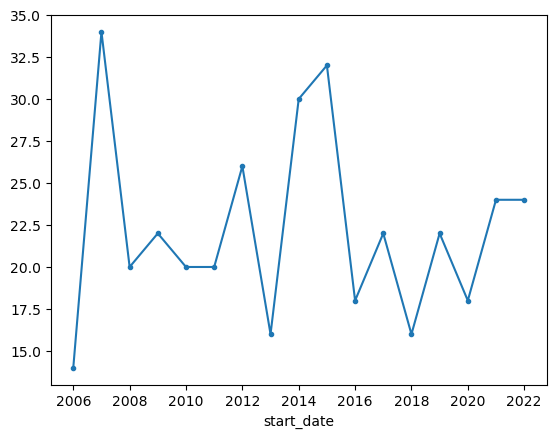

In [49]:
df.groupby(df.start_date.dt.year).count()['case_number'].plot(marker='.')

In [70]:
df.groupby(df.start_date.dt.year).count().satellite.mean()

np.float64(22.235294117647058)

The original sample selection is based on a random sample from a slightly different, overlapping region from an earlier iteration of the planned study. If data was equally likely to come from anywhere in the area, then we would just need to adjust sample size to proportionately come from the different area. However, the difference in *MIZ* area is the important thing, and that varies by day and year. So we do a numerical experiment to see the fraction of data by month that should come from the additional data regions.

This code takes the old region bounds, and computes the fraction per month expected to come from old vs. new regions.

In [100]:
df["left_x"] = df.center_x - 50e3
df["right_x"] = df.center_x + 50e3
df["upper_y"] = df.center_y + 50e3
df["lower_y"] = df.center_y - 50e3



In [103]:
# Overlap bounds?
out_of_bounds = []
for region in regions.index:
    df_sel = df.loc[(df.region == region) & (df.satellite == 'aqua'), :]
    x_bounds = (df_sel.left_x < regions.loc[region].left_x) | (df_sel.right_x > regions.loc[region].right_x)
    y_bounds = (df_sel.lower_y < regions.loc[region].lower_y) | (df_sel.upper_y > regions.loc[region].upper_y)
    df_sel.loc[x_bounds | y_bounds]
    out_of_bounds.append(df_sel.copy())

In [107]:
df_sel = pd.concat(out_of_bounds)
df_sel.iloc[0, :]

Unnamed: 0                                    210
case_number                                   106
region                              greenland_sea
satellite                                    aqua
start_date                    2014-09-11 00:00:00
pass_time                     2014-09-11 10:55:00
center_lon                                -13.431
center_lat                                78.7934
center_x                                   637500
center_y                                 -1037500
sea_ice_fraction                             0.92
mean_sea_ice_concentration                  0.715
visible_sea_ice                               yes
visible_landfast_ice                          yes
visible_floes                                 yes
visible_water                                 yes
number_floes                                    4
mean_floe_size                              402.8
total_floe_area                            1611.0
minimum_floe_size                              98


In [113]:
regions.loc['greenland_sea', ['upper_y', 'lower_y', 'left_x', 'right_x']]

upper_y    -725683.0
lower_y   -2234665.0
left_x      290374.0
right_x    1244051.0
Name: greenland_sea, dtype: object

In [140]:
# This one is taking ages to run
regions_to_sample = [
    'east_siberian_sea']
results = {}
for region in regions_to_sample:
    row = regions.loc[region]
    test = find_candidates(n_samples=50,
                    region_info=row,
                    dx=100,
                    sic_path=sic_dataloc,
                    sif_threshold=0.25,
                    margin=50, start_year=2006, end_year=2023,
                    min_samples_per_month=1) # Margin keeps the edges of boxes inside the outer bounds.
    results[region] = test
    print(region)

east_siberian_sea


In [141]:
results[region][pd.to_datetime(results[region].start_date).dt.month == 8]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
0,east_siberian_sea,2011-08-15,-177.852415,76.989752,-1037500.0,962500.0,1.0,0.818,8


In [144]:
regions_to_sample = [
    'laptev_sea']
for region in regions_to_sample:
    row = regions.loc[region]
    test = find_candidates(n_samples=50,
                    region_info=row,
                    dx=100,
                    sic_path=sic_dataloc,
                    sif_threshold=0.25,
                    margin=50, start_year=2006, end_year=2023,
                    min_samples_per_month=1) # Margin keeps the edges of boxes inside the outer bounds.
    results[region] = test
results[region][pd.to_datetime(results[region].start_date).dt.month == 8]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
0,laptev_sea,2014-08-05,123.690068,80.021798,212500.0,1062500.0,0.68,0.465,8


In [137]:
regions_to_sample = [
    'hudson_bay']
for region in regions_to_sample:
    row = regions.loc[region]
    test = find_candidates(n_samples=50,
                    region_info=row,
                    dx=100,
                    sic_path=sic_dataloc,
                    sif_threshold=0.25,
                    margin=50, start_year=2017, end_year=2017,
                    min_samples_per_month=5) # Margin keeps the edges of boxes inside the outer bounds.
    results[region] = test
    print(region)
results[region][pd.to_datetime(results[region].start_date).dt.month == 7]

hudson_bay


,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
4,hudson_bay,2017-07-23,-84.702952,65.613082,-1712500.0,-2062500.0,0.44,0.757,7
5,hudson_bay,2017-07-02,-90.000000,57.720255,-2537500.0,-2537500.0,1.00,0.655,7
7,hudson_bay,2017-07-21,-85.749345,66.119475,-1712500.0,-1987500.0,0.32,0.728,7
15,hudson_bay,2017-07-20,-84.702952,65.613082,-1712500.0,-2062500.0,0.40,0.800,7
18,hudson_bay,2017-07-20,-84.702952,65.613082,-1712500.0,-2062500.0,0.40,0.800,7


In [138]:
regions_to_sample = [
    'laptev_sea']
for region in regions_to_sample:
    row = regions.loc[region]
    test = find_candidates(n_samples=50,
                    region_info=row,
                    dx=100,
                    sic_path=sic_dataloc,
                    sif_threshold=0.25,
                    margin=50, start_year=2011, end_year=2011,
                    min_samples_per_month=5) # Margin keeps the edges of boxes inside the outer bounds.
    results[region] = test
    print(region)
results[region][pd.to_datetime(results[region].start_date).dt.month == 3]

laptev_sea


,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
6,laptev_sea,2011-03-29,110.045249,77.196809,587500.0,1262500.0,0.92,0.902,3
20,laptev_sea,2011-03-18,109.604088,77.403217,587500.0,1237500.0,1.00,0.862,3
24,laptev_sea,2011-03-30,109.212672,78.630318,537500.0,1112500.0,1.00,0.888,3
28,laptev_sea,2011-03-28,106.260205,77.805317,637500.0,1162500.0,0.92,0.872,3
29,laptev_sea,2011-03-28,124.354337,74.476054,312500.0,1662500.0,1.00,0.940,3


In [152]:
regions_to_sample = [
    'sea_of_okhostk']
for region in regions_to_sample:
    row = regions.loc[region]
    test = find_candidates(n_samples=100,
                    region_info=row,
                    dx=100,
                    sic_path=sic_dataloc,
                    sif_threshold=0.25,
                    margin=50, start_year=2006, end_year=2023,
                    min_samples_per_month=15) # Margin keeps the edges of boxes inside the outer bounds.
    results[region] = test
    print(region)
results[region][pd.to_datetime(results[region].start_date).dt.month == 6]

sea_of_okhostk


,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
12,sea_of_okhostk,2011-06-01,141.421061,54.975788,-437500.0,3887500.0,0.48,0.395,6
15,sea_of_okhostk,2015-06-13,138.089156,54.713224,-212500.0,3937500.0,0.60,0.773,6
20,sea_of_okhostk,2015-06-02,137.779167,55.355201,-187500.0,3862500.0,0.44,0.624,6
22,sea_of_okhostk,2020-06-10,136.657615,55.168916,-112500.0,3887500.0,0.56,0.609,6
23,sea_of_okhostk,2016-06-12,141.760353,53.054551,-487500.0,4112500.0,0.28,0.747,6
27,sea_of_okhostk,2006-06-29,137.025694,55.162141,-137500.0,3887500.0,0.56,0.524,6
28,sea_of_okhostk,2016-06-13,162.255328,60.648892,-1487500.0,2887500.0,0.32,0.471,6
37,sea_of_okhostk,2012-06-01,141.842773,58.802983,-412500.0,3437500.0,0.40,0.521,6
39,sea_of_okhostk,2020-06-08,137.363247,54.733232,-162500.0,3937500.0,0.32,0.691,6
40,sea_of_okhostk,2020-06-07,136.636577,54.747913,-112500.0,3937500.0,0.56,0.649,6


,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration
month,,,,,,,,
3,15,15,15,15,15,15,15,15
4,15,15,15,15,15,15,15,15
5,15,15,15,15,15,15,15,15
6,15,15,15,15,15,15,15,15


## Drawing new samples
This section draws new samples to match the improved boundaries.

Along with the change in boundaries to better match standard marginal sea definitions and avoid overlaps, we focus on the time range where MASIE sea ice extent data is available. Thus we need to see how many new samples to draw to replace the discarded samples. 

### Simple cases
Baffin Bay, Beaufort Sea, East Siberian Sea, Sea of Okhostk, and Laptev Sea all are only reduced in size: thus, we keep all samples from the original that are still in the time range, and draw new samples to bring the numbers back to the init counts.

Where we've only discarded samples from restricting the area and date range, we add new samples to bring the numbers to the expected count. We draw the maximum number of samples needed by month, then take the samples in the order they were drawn.

# Complex cases
For cases where is a shift in the coverage area, we draw a full new sample first. Then, we keep the original samples up to the number of samples in the original region in the candidate list. Finally, we add samples from the candidate list until we have the original number of samples per month.

# Converting to a file to run on Oscar
For the IFT-Pipeline, we need a CSV with case names and the coordinates for the bounding boxes. We'll reformat and save this there.

In [518]:
import pandas as pd
df = pd.read_csv('../data/metadata/validation_dataset_case_list.csv', index_col=0, parse_dates=['start_date'])
# fullname,case_number,location,dx,left_x,right_x,lower_y,top_y,center_x,center_y,center_lat,center_lon,startdate,enddate

# 
df['fullname'] = ['-'.join([str(cn).zfill(3), r, '100km', sd.strftime('%Y-%m-%d')]) for cn, r, sd in zip(df.case_number, df.region, df.start_date)]
dx = 50e3
df['left_x'] = df['center_x'] - dx
df['right_x'] = df['center_x'] + dx
df['lower_y'] = df['center_y'] - dx
df['top_y'] = df['center_y'] + dx
df['dx'] = '100km'
df.rename({'start_date': 'startdate', 'region': 'location'}, axis=1, inplace=True)
df['enddate'] = [sd + pd.to_timedelta(1, unit='d') for sd in df['startdate']]
df['case_number'] = [str(x).zfill(3) for x in df['case_number']]

In [521]:
df[['fullname','case_number','location','dx','left_x','right_x',
    'lower_y','top_y','center_x','center_y','center_lat','center_lon',
    'startdate','enddate']].to_csv('../data/metadata/iftp_case_list.csv')

# Drawing new samples based on the MASIE results

I first checked whether any of the original sample were available as "back up" choices. Unfortunately, all of these were before 2006, so the MASIE data isn't available. Next step is to use the sampling routine.

 Samples to replace:
| Number | Regions | Date | 
| --- | --- | --- |
| 38 |	barents_kara_seas |	2016-08-29	|
| 40 |	barents_kara_seas |	2011-09-25	|
| 102 |	east_siberian_sea |	2011-07-13	|
| 135 |	hudson_bay		 |	2006-07-18	|
| 175 |	sea_of_okhostk |	2006-06-29	|
| 64 | bering_chukchi_seas | 2007-07-27 |
| 83 | bering_chukchi_seas | 2011-07-15 |
| 106 | greenland_sea | 2017-09-13 |
| 134 | hudson_bay | 2010-08-12 |
| 136 | hudson_bay | 2006-08-02 |

To find the new samples, I ran the sampling routine, then examined the Worldview imagery for that date to make sure the summer SIC bias wasn't affecting the choice.


In [16]:
# The merged list has the updated values from resampling.
updated_list = pd.read_csv('../data/metadata/merged_validation_table.csv', index_col='case_number')

In [17]:
# Round one: 38, 40, 102, 135, 175
# updated_list.loc[[38, 40, 102, 135, 175],['region', 'start_date', 'center_lon', 'center_lat']]

# Round two: 64, 83, 106, 134, 136
updated_list.loc[[64, 83, 106, 134, 136],['region', 'start_date', 'center_lon', 'center_lat']]

,region,start_date,center_lon,center_lat
case_number,,,,
64,bering_chukchi_seas,2007-07-27,-179.618034,65.870007
64,bering_chukchi_seas,2007-07-27,-179.618034,65.870007
83,bering_chukchi_seas,2011-07-15,-162.434985,66.528209
83,bering_chukchi_seas,2011-07-15,-162.434985,66.528209
106,greenland_sea,2017-09-13,-24.249204,70.321239
106,greenland_sea,2017-09-13,-24.249204,70.321239
134,hudson_bay,2010-08-12,-87.006868,65.369332
134,hudson_bay,2010-08-12,-87.006868,65.369332
136,hudson_bay,2006-08-02,-86.308614,65.039779


In [ ]:
init_case_list['new_case_number'] = np.nan
for row, data in updated_list.iterrows():
    if data.init_case_number > 0:
        init_case_list.loc[data.init_case_number, 'new_case_number'] = row

# Checking if any of the original sample can be used.
# In both cases, my finding was no, none of the original sample was appropriate (no ice)
init_case_list.loc[(init_case_list.new_case_number.isnull() & (init_case_list.month == 7)) &\
                    (init_case_list.start_date.dt.year >= 2006)]

Process: we use the find candidates function to identify a list of cases, then look at each individually. Starting from the first, we check the days around the sampled day in the Worldview imagery. If it's a region within the sea ice region, then we keep it.

In [29]:
region = 'hudson_bay'
n = 50
candidates = find_candidates(n_samples=n,
                region_info=regions.loc[region],
                dx=100,
                sic_path=sic_dataloc,
                sif_threshold=0.25,
                margin=50, start_year=2006, end_year=2022,
                min_samples_per_month=n)

In [67]:
candidates.loc[[1],:]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
1,east_siberian_sea,2022-07-02,155.013567,71.609279,-687500.0,1887500.0,1.0,0.855,7


In [70]:
candidates.loc[[9],:]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
9,hudson_bay,2017-07-06,-91.780642,59.221811,-2487500.0,-2337500.0,0.64,0.43,7


In [73]:
# 9 - no ice
candidates.loc[[17],:]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
17,sea_of_okhostk,2010-06-04,139.6859,55.708056,-312500.0,3812500.0,0.8,0.536,6


In [64]:
# Barents Kara Seas in September will likely only have ice
# north of approx 80 latitude
new_samples = [5, 0]
sample_numbers = [38, 40]
candidates.loc[new_samples]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
5,barents_kara_seas,2014-08-02,88.339718,78.769967,887500.0,837500.0,1.0,0.752,8
0,barents_kara_seas,2007-09-12,12.757532,81.149074,812500.0,-512500.0,0.6,0.696,9


In [24]:
new_samples = [0, 6]
candidates.loc[new_samples]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
0,bering_chukchi_seas,2015-07-16,-167.047235,73.368234,-1537500.0,962500.0,0.56,0.455,7
6,bering_chukchi_seas,2018-07-26,-161.737110,72.937768,-1662500.0,837500.0,0.96,0.497,7


In [28]:
candidates.loc[[1]]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
1,greenland_sea,2014-09-11,-13.431029,78.793415,637500.0,-1037500.0,0.92,0.715,9


In [33]:
# Checked and rejected:
# 5, 12, 17, 19, 32, 35
# 41, 42, 44, 50, 54, 74
# 78, 93, 
new_samples = [85, 97]
candidates.loc[new_samples,]

,region,start_date,center_lon,center_lat,center_x,center_y,sea_ice_fraction,mean_sea_ice_concentration,month
85,hudson_bay,2015-08-10,-85.749345,66.119475,-1712500.0,-1987500.0,1.0,0.732,8
97,hudson_bay,2012-08-14,-84.364059,65.442785,-1712500.0,-2087500.0,1.0,0.806,8


New samples:
|case_number | region 	| start_date 	| center_lon 	| center_lat 	| center_x 	| center_y 	| sea_ice_fraction 	| mean_sea_ice_concentration 	| month |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | -- |
| 38 |	barents_kara_seas |	2014-08-02 | 88.339718 | 78.769967 	| 887500.0 	| 837500.0 |	1.0 	| 0.752 | 8 |
| 40 |	barents_kara_seas |	2007-09-12 | 12.757532 	| 81.149074 | 812500.0 	| -512500.0 | 0.6 | 0.696 | 9 |
| 102 |	east_siberian_sea |	2022-07-02 | 155.013567 | 71.609279 | -687500.0 | 1887500.0 | 1.0 | 0.855 | 7 |
| 135 |	hudson_bay 	| 2017-07-06	| -91.780642	| 59.221811	| -2487500.0	| -2337500.0	| 0.64	| 0.43	| 7 |
| 175 |	sea_of_okhostk | 2010-06-04 | 139.6859 | 55.708056 | -312500.0 | 3812500.0 | 0.8 | 0.536 | 6 |
| 64 | bering_chukchi_seas | 2015-07-16 | -167.047235 | 73.368234 | -1537500.0 | 962500.0 | 0.56 | 0.455 | 7| 
| 83 | bering_chukchi_seas | 2018-07-26 | -161.737110 | 72.937768 | -1662500.0 | 837500.0 | 0.96 | 0.497 | 7| 
| 106 | greenland_sea | 2014-09-11 | -13.431029 | 78.793415 | 637500.0 | -1037500.0 | 0.92 | 0.715 | 9 | 
| 134 | hudson_bay | 2015-08-10 | -85.749345 | 66.119475 | -1712500.0 | -1987500.0 | 1.0 | 0.732 | 8 | 
| 136 | hudson_bay | 2012-08-14 | -84.364059 | 65.442785 | -1712500.0 | -2087500.0 | 1.0 | 0.806 | 8 | 


In [38]:
# Merging to make the IFTP case list
case_list = pd.read_csv('../data/metadata/iftp_case_list.csv', index_col=0)

new_samples = pd.DataFrame(data=[ 
    [38,'barents_kara_seas','2014-08-02',88.339718,78.769967,887500.0,837500.0,1.0,0.752],
    [40,'barents_kara_seas','2007-09-12',12.757532,81.149074,812500.0,-512500.0,0.6,0.696],
    [102,'east_siberian_sea','2022-07-02',155.013567,71.609279,-687500.0,1887500.0,1.0,0.855],
    [135,'hudson_bay','2017-07-06',-91.780642,59.221811,-2487500.0,-2337500.0,0.64,0.43],
    [175,'sea_of_okhostk','2010-06-04',139.6859,55.708056,-312500.0,3812500.0,0.8,0.536],
    [64,'bering_chukchi_seas','2015-07-16',-167.047235,73.368234,-1537500.0,962500.0,0.56,0.455],
    [83,'bering_chukchi_seas','2018-07-26',-161.737110,72.937768,-1662500.0,837500.0,0.96,0.497],
    [106,'greenland_sea','2014-09-11',-13.431029,78.793415,637500.0,-1037500.0,0.92,0.715],
    [134,'hudson_bay','2015-08-10',-85.749345,66.119475,-1712500.0,-1987500.0,1.0,0.732],
    [136,'hudson_bay','2012-08-14',-84.364059,65.442785,-1712500.0,-2087500.0,1.0,0.806]],
                        columns=['case_number', 	'location', 	'startdate', 	'center_lon',
                                 'center_lat', 	'center_x',  'center_y', 	'sea_ice_fraction',
                                 'mean_sea_ice_concentration'])
new_samples['enddate'] = [(pd.to_datetime(sd) + pd.to_timedelta('1d')).strftime('%Y-%m-%d') for sd in new_samples['startdate']]
new_samples['left_x'] = new_samples['center_x'] - 50e3 
new_samples['right_x'] = new_samples['center_x'] + 50e3 
new_samples['lower_y'] = new_samples['center_y'] - 50e3
new_samples['top_y'] = new_samples['center_y'] + 50e3
new_samples['dx'] = '100km'
column_order = ['fullname', 'case_number', 'location', 'dx', 'left_x', 'right_x',
       'lower_y', 'top_y', 'center_x', 'center_y', 'center_lat', 'center_lon',
       'startdate', 'enddate']
new_samples['fullname'] = ['-'.join([str(cn).zfill(3), rg, '100km', sd]) for cn, rg, sd in zip(new_samples.case_number,
                                                                                             new_samples.location,
                                                                                             new_samples.startdate)]
keep_idx = [x for x in case_list.index if case_list.loc[x, 'case_number'] not in new_samples['case_number'].values]
pd.concat([case_list.loc[keep_idx], new_samples]).sort_values('case_number').to_csv('../data/metadata/iftp_case_list_updated.csv', index=False)

In [64]:
# Update the validation case list file
case_list = pd.read_csv('../data/metadata/validation_dataset_case_list.csv', index_col=0)
case_list = case_list.set_index('case_number', drop=True)

# update list:
for cn in new_samples.case_number:
    for col in case_list:
        if col in new_samples.columns:
            case_list.loc[cn, col] = new_samples.loc[new_samples.case_number == cn, col].squeeze()
    case_list.loc[cn, 'month'] = pd.to_datetime(case_list.loc[cn, 'start_date']).month
    case_list.loc[cn, 'init_case_number'] = -1
    case_list.loc[cn,'start_date'] = new_samples.loc[new_samples.case_number == cn, 'startdate'].squeeze()

In [65]:
case_list.loc[new_samples['case_number']]

,region,start_date,center_lon,center_lat,center_x,center_y,month,sea_ice_fraction,mean_sea_ice_concentration,init_case_number
case_number,,,,,,,,,,
38,barents_kara_seas,2014-08-02,88.339718,78.769967,887500.0,837500.0,8,1.00,0.752,-1
40,barents_kara_seas,2007-09-12,12.757532,81.149074,812500.0,-512500.0,9,0.60,0.696,-1
102,east_siberian_sea,2022-07-02,155.013567,71.609279,-687500.0,1887500.0,7,1.00,0.855,-1
135,hudson_bay,2017-07-06,-91.780642,59.221811,-2487500.0,-2337500.0,7,0.64,0.430,-1
175,sea_of_okhostk,2010-06-04,139.685900,55.708056,-312500.0,3812500.0,6,0.80,0.536,-1
64,bering_chukchi_seas,2015-07-16,-167.047235,73.368234,-1537500.0,962500.0,7,0.56,0.455,-1
83,bering_chukchi_seas,2018-07-26,-161.737110,72.937768,-1662500.0,837500.0,7,0.96,0.497,-1
106,greenland_sea,2014-09-11,-13.431029,78.793415,637500.0,-1037500.0,9,0.92,0.715,-1
134,hudson_bay,2015-08-10,-85.749345,66.119475,-1712500.0,-1987500.0,8,1.00,0.732,-1


In [67]:
! mv ../data/metadata/validation_dataset_case_list.csv ../data/metadata/init_validation_dataset_case_list.csv
case_list.sort_index().to_csv('../data/metadata/validation_dataset_case_list.csv')

# Dataset statistics

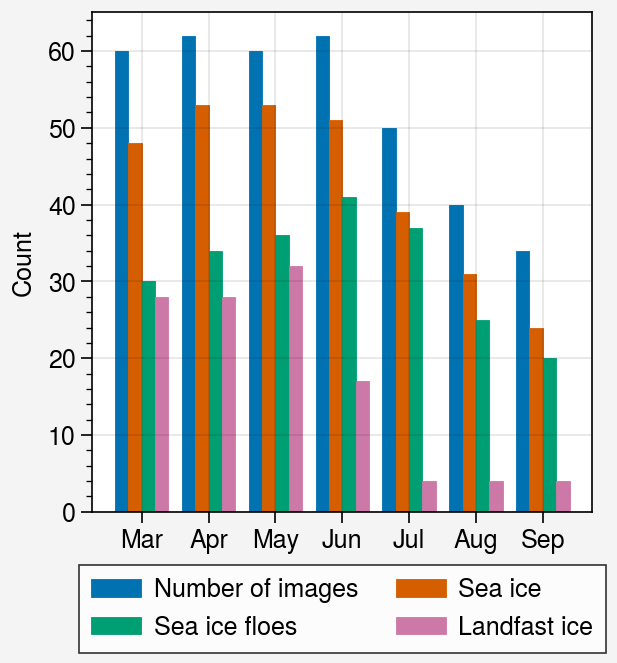

In [68]:
import proplot as pplt
import pandas as pd
import numpy as np

fig, ax = pplt.subplots()

df = pd.read_csv('../data/metadata/merged_validation_table.csv', parse_dates=['start_date'])
df['month'] = df['start_date'].dt.month
df.loc[:, 'visible_sea_ice'] = df.loc[:, 'visible_sea_ice'].where(df.loc[:, 'visible_sea_ice']=='yes')
df.loc[:, 'visible_landfast_ice'] = df.loc[:, 'visible_landfast_ice'].where(df.loc[:, 'visible_landfast_ice']=='yes')
df.loc[:, 'visible_floes'] = df.loc[:, 'visible_floes'].where(df.loc[:, 'visible_floes']=='yes')
df.rename({'cloud_fraction_manual': 'Number of images',
                  'visible_sea_ice': 'Sea ice',
                  'visible_floes': 'Sea ice floes',
                  'visible_landfast_ice': 'Landfast ice'}, axis=1, inplace=True)

ax.bar(df.loc[:, ['month', 'Number of images', 'Sea ice', 'Sea ice floes', 'Landfast ice']].groupby('month').count())
ax.legend(loc='b', ncols=2)
ax.format(ylabel='Count', xlabel='', xlocator=np.arange(3, 10),
          xformatter=['Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep'],
          xtickminor=False)
fig.save('../figures/random_sample_summary_chart.png', dpi=300)

# Analysis progress

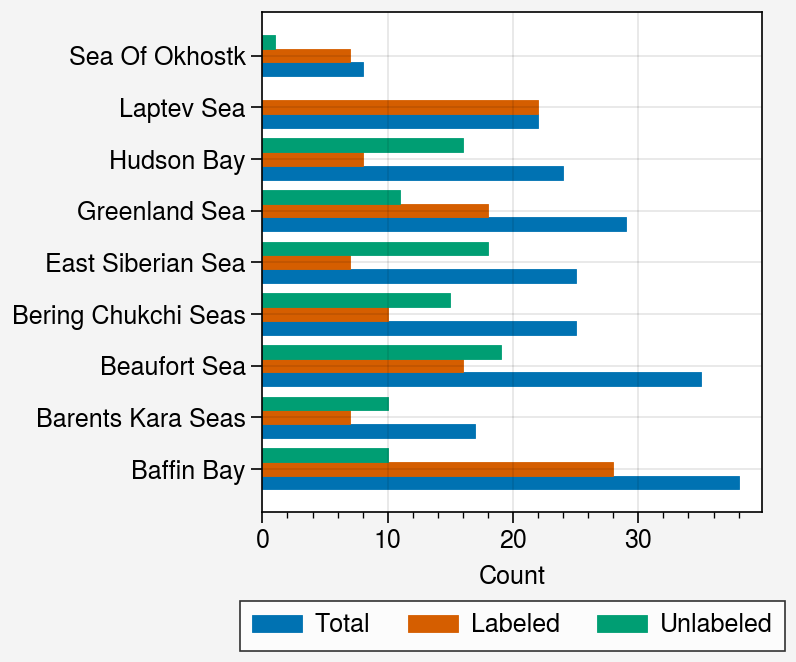

In [69]:
df = pd.read_csv('../data/metadata/merged_validation_table.csv', parse_dates=['start_date'])
df['month'] = df['start_date'].dt.month
total_to_label = df.loc[df.visible_floes == 'yes'].groupby('region').count()['case_number']
total_labeled = df.loc[(df.visible_floes == 'yes') & df.fl_analyst.notnull(),:].groupby('region').count()['case_number']
total_unlabeled = df.loc[(df.visible_floes == 'yes') & df.fl_analyst.isnull(),:].groupby('region').count()['case_number']
df2 = pd.DataFrame({'Total': total_to_label, 'Labeled': total_labeled, 'Unlabeled': total_unlabeled})
df2.index = [x.replace('_', ' ').title() for x in df2.index]

fig, ax = pplt.subplots()
ax.barh(df2)
ax.format(xlabel='Count')
ax.legend(loc='b')

In [3]:
import pandas as pd

In [5]:
day_of_year = 173
pd.to_datetime('2001-01-01') + pd.to_timedelta(day_of_year - 1, unit='d')

Timestamp('2001-06-22 00:00:00')